# Proyecto 3 — Pasos 5 y 6: implementación con CUDA y análisis

**CC3069 · UVG · Semestre II 2026**

Este notebook contiene el **código original secuencial** (Laboratorio 3, Keras en CPU) y la **versión optimizada**
(preparación de imágenes en todos los núcleos del CPU + entrenamiento en GPU con CUDA), con la separación del flujo de
trabajo a la vista. Los pasos 1 a 4 están en `secuencial_y_diseno.ipynb`.

| Sección | Contenido |
|---|---|
| **0** | Entorno: CPU y GPU detectados |
| **1** | Código **original secuencial** (Lab 3) |
| **2** | Código **nuevo**: fase A (CPU), puente CPU → GPU, fase B (GPU) |
| **3** | Demostración en vivo de cada fase con su tiempo |
| **4** | Kernel propio con Numba CUDA (Adam) |
| **5** | Mediciones (equipo `pc2`) y evidencia de ejecución |
| **6** | Paso 6: análisis y conclusiones |
| **7** | Pruebas de equivalencia paralelo / secuencial |

## 0. Entorno

In [1]:
import sys, ast, re, subprocess, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, Image, display
from comun import config

LAB = ROOT / "secuencial" / "lab3_original"      # código del Laboratorio 3, sin modificar
NEW = ROOT / "paralelo_cuda"                       # versión nueva (GPU)
PREP = ROOT / "preparacion_datos"                  # versión nueva (CPU)

def source_of(path, name):
    """Código fuente de una función dentro de un archivo (sin importarlo)."""
    text = Path(path).read_text(encoding="utf-8")
    for n in ast.parse(text).body:
        if isinstance(n, ast.FunctionDef) and n.name == name:
            return ast.get_source_segment(text, n)

def mostrar_md(path, desde=None):
    """Muestra un .md del proyecto incrustando sus imágenes (rutas relativas al propio archivo)."""
    path = Path(path); t = path.read_text(encoding="utf-8")
    if desde:
        t = t[t.index(desde):]
    pos = 0
    for m in re.finditer(r"!\[([^\]]*)\]\(([^)]+)\)", t):
        display(Markdown(t[pos:m.start()]))
        display(Image(filename=str((path.parent / m.group(2)).resolve())))
        pos = m.end()
    display(Markdown(t[pos:]))

print("CPU:", __import__("os").cpu_count(), "hilos lógicos")
print("PyTorch", torch.__version__, "| CUDA runtime", torch.version.cuda, "| CUDA disponible:", torch.cuda.is_available())
p = torch.cuda.get_device_properties(0)
print(f"GPU: {p.name} | {p.total_memory/2**30:.1f} GB | {p.multi_processor_count} multiprocesadores | capacidad {p.major}.{p.minor}")
print("Dataset:", config.TRAIN_DIR, "| existe:", config.TRAIN_DIR.is_dir())

CPU: 12 hilos lógicos
PyTorch 2.11.0+cu128 | CUDA runtime 12.8 | CUDA disponible: True
GPU: NVIDIA GeForce RTX 4060 Ti | 8.0 GB | 34 multiprocesadores | capacidad 8.9
Dataset: D:\Tareas\Data Science\Laboratorio 3\data\asl_alphabet_train | existe: True


## 1. Código original secuencial (Laboratorio 3, Keras / CPU)

Se ejecuta **sin modificar** (`secuencial/lab3_original/`). Preparar las imágenes es un bucle de un solo hilo y el
entrenamiento es `model.fit` de Keras, que en Windows nativo corre en CPU (TensorFlow ≥ 2.11 no usa la GPU).

**Preparar cada imagen y el bucle secuencial:**

In [2]:
print(source_of(LAB / "preprocessing.py", "preprocess_image"))
print()
print(source_of(LAB / "preprocessing.py", "load_preprocessed_batch"))

def preprocess_image(
    image_path: Path,
    image_size: tuple[int, int] = DEFAULT_IMAGE_SIZE,
) -> np.ndarray:
    """Carga una imagen como RGB, la reduce y normaliza sus píxeles a [0, 1]."""
    width, height = image_size
    if width <= 0 or height <= 0:
        raise ValueError("Las dimensiones de salida deben ser positivas")

    with Image.open(image_path) as image:
        rgb = image.convert("RGB")
        resized = rgb.resize(image_size, Image.Resampling.LANCZOS)
        array = np.asarray(resized, dtype=np.float32) / 255.0
    return array

def load_preprocessed_batch(
    manifest: pd.DataFrame,
    image_root: Path,
    image_size: tuple[int, int] = DEFAULT_IMAGE_SIZE,
) -> tuple[np.ndarray, np.ndarray]:
    """Carga un subconjunto pequeño como arreglos NumPy para análisis o prueba."""
    validate_manifest(manifest)
    root = Path(image_root)
    images = [preprocess_image(root / row.path, image_size) for row in manifest.itertuples()]
    return np.stack(images), manif

**Red CNN #2 en Keras** (la que más tarda):

In [3]:
print(source_of(LAB / "models.py", "build_cnn_regularized"))

def build_cnn_regularized(
    input_shape: tuple[int, int, int] = DEFAULT_INPUT_SHAPE,
    num_classes: int = NUM_CLASSES,
) -> keras.Model:
    """CNN más profunda con BatchNorm y Dropout para controlar overfitting.

    Tres bloques conv-conv-pool con normalización por lotes, seguidos de
    una capa densa con dropout fuerte antes de la salida.
    """
    model = keras.Sequential(
        [
            keras.Input(shape=input_shape),
            layers.Conv2D(32, 3, activation="relu", padding="same"),
            layers.BatchNormalization(),
            layers.Conv2D(32, 3, activation="relu", padding="same"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(),
            layers.Dropout(0.25),
            layers.Conv2D(64, 3, activation="relu", padding="same"),
            layers.BatchNormalization(),
            layers.Conv2D(64, 3, activation="relu", padding="same"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(),
            la

**Ciclo de medición del secuencial** (`secuencial/medir_secuencial.py`): cada tarea se cronometra con `time.perf_counter()` y se repite 3 veces.

In [4]:
texto = (ROOT / "secuencial" / "medir_secuencial.py").read_text(encoding="utf-8")
ini = texto.index("for rep in range(1, args.reps + 1):")
fin = texto.index('mark("idle")')
print(texto[ini:fin])

for rep in range(1, args.reps + 1):
            print(f"\n--- Repetición {rep}/{args.reps} ---")
            mark(f"preprocess_r{rep}")
            t0 = time.perf_counter()
            images, labels = lab_prep.load_preprocessed_batch(manifest, TRAIN_DIR)   # código original, NHWC
            record(rep, "preprocess", "-", time.perf_counter() - t0, images=len(manifest))
            y_all = np.array([index[x] for x in labels], dtype=np.int64)
            split = manifest["split"].to_numpy()
            x_tr, y_tr = images[split == "train"], y_all[split == "train"]
            x_va, y_va = images[split == "validation"], y_all[split == "validation"]
            x_te, y_te = images[split == "test"], y_all[split == "test"]
            del images  # libera ~0.85 GB: evita tener el dataset duplicado en RAM junto a TensorFlow

            for name in args.models:
                tf.keras.utils.set_random_seed(SEED)
                tf.keras.backend.clear_session()
                model = builde

## 2. Código nuevo: separación CPU / GPU

```
 DISCO ──► [ FASE A · CPU, todos los núcleos ] ──► [ PUENTE: una sola copia ] ──► [ FASE B · GPU con CUDA ]
           leer JPG · reducir a 64×64 · normalizar     816 MiB, CPU → GPU           entrenar y evaluar las redes
           preparacion_datos/preprocesamiento.py        paralelo_cuda/entrenamiento.py     paralelo_cuda/
```

La GPU **solo** hace la matemática de la red; leer y decodificar imágenes se queda en el CPU
(ver la justificación en `docs/03` y la discusión del paso 6).

### Fase A (CPU): reparto de las imágenes entre procesos
Bloques de 64 imágenes → un `ProcessPoolExecutor` con un proceso por hilo del CPU (procesos y no hilos, porque la
decodificación de JPEG no se beneficia de los hilos de Python). Devuelve el mismo resultado que el bucle secuencial.

In [5]:
print(source_of(PREP / "preprocesamiento.py", "_decode_resize_chunk"))
print()
print(source_of(PREP / "preprocesamiento.py", "load_preprocessed_parallel"))

def _decode_resize_chunk(args: tuple[str, list[str], tuple[int, int]]) -> np.ndarray:
    """Tarea de un worker: decodifica y reduce un bloque de imágenes -> uint8.

    Devuelve uint8 (no float32) para que el envío entre procesos pese 4x menos;
    la normalización se hace una sola vez, vectorizada, en el proceso padre.
    """
    root, rel_paths, size = args
    out = np.empty((len(rel_paths), size[1], size[0], 3), dtype=np.uint8)
    for i, rel in enumerate(rel_paths):
        with Image.open(os.path.join(root, rel)) as image:
            out[i] = np.asarray(
                image.convert("RGB").resize(size, Image.Resampling.LANCZOS), dtype=np.uint8
            )
    return out

def load_preprocessed_parallel(
    manifest: pd.DataFrame,
    image_root: Path,
    image_size: tuple[int, int] = IMAGE_SIZE,
    workers: int | None = None,
    chunk_size: int = 64,
) -> tuple[np.ndarray, np.ndarray]:
    """VERSIÓN PARALELA: reparte bloques de ``chunk_size`` imágenes entre ``workers`` 

### Puente: una sola copia CPU → GPU

In [6]:
print(source_of(NEW / "entrenamiento.py", "to_device"))

def to_device(array: np.ndarray, device: torch.device) -> torch.Tensor:
    """Transferencia CPU -> dispositivo (cuando device es CUDA, es la copia H2D)."""
    return torch.from_numpy(array).to(device, non_blocking=False)


### Fase B (GPU): red y bucle de entrenamiento
Las redes están portadas de Keras a PyTorch conservando capas, inicialización, hiperparámetros y número de parámetros
(se comprueba en `tests/`). El bucle de entrenamiento no toca el CPU: los lotes se extraen **por índice dentro de la GPU**,
no se llama a `.item()` por lote y se sincroniza (`torch.cuda.synchronize()`) antes de leer el reloj.

In [7]:
print(source_of(NEW / "modelos.py", "build_cnn_regularized"))
print()
print(source_of(NEW / "entrenamiento.py", "fit"))

def build_cnn_regularized(num_classes: int = NUM_CLASSES) -> nn.Module:
    """CNN #2: tres bloques conv + BatchNorm + Dropout (2,246,589 parámetros)."""
    model = nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), _bn(32),
        nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), _bn(32),
        nn.MaxPool2d(2), nn.Dropout(0.25),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), _bn(64),
        nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), _bn(64),
        nn.MaxPool2d(2), nn.Dropout(0.25),
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), _bn(128),
        nn.MaxPool2d(2), nn.Dropout(0.25),
        nn.Flatten(),
        nn.Linear(128 * 8 * 8, 256), nn.ReLU(), _bn(256, two_d=False), nn.Dropout(0.5),
        nn.Linear(256, num_classes),
    )
    model.apply(_init_keras_like)
    return model

def fit(
    model: nn.Module,
    x_train: torch.Tensor,
    y_train: torch.Tensor,
    x_val: torch.Tensor,
    y_val: torch.Tensor,
    lr: float,
    max_epochs: int,
    batc

## 3. Demostración en vivo de cada fase

Mismo flujo que `paralelo_cuda/medir_cuda.py`, una sola vez y con la CNN #2 durante 1 época. (Las mediciones oficiales,
con 3 repeticiones y 3 épocas, están en la sección 5.)

> **Dos aclaraciones sobre esta demostración:** (1) la época de la CNN #2 tarda más que en las mediciones oficiales
> (≈ 2-4 s por época) porque aquí incluye la inicialización única de CUDA y el autotune de cuDNN del proceso nuevo; las
> mediciones oficiales miden eso aparte (`cuda_warmup`, 5.0 s). (2) Con 1 época la exactitud de prueba aún es ≈ azar
> (1 / 29 ≈ 0.034); no es lo que se mide aquí, solo se ejecuta el flujo completo.

In [8]:
from preparacion_datos.preprocesamiento import load_preprocessed_parallel, to_nchw, class_names, encode_labels
from paralelo_cuda.modelos import build_model, count_parameters
from paralelo_cuda.entrenamiento import fit, evaluate, set_seed, sync, to_device

device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
manifest = pd.read_csv(config.SPLIT_MANIFEST).reset_index(drop=True)
classes = class_names(manifest)

# --- FASE A (CPU, todos los núcleos) -----------------------------------------
t0 = time.perf_counter()
images, labels = load_preprocessed_parallel(manifest, config.TRAIN_DIR, config.IMAGE_SIZE)
t_prep = time.perf_counter() - t0
x_all, y_all = to_nchw(images), encode_labels(labels, classes)
split = manifest["split"].to_numpy()
parts = {s: (x_all[split == s], y_all[split == s]) for s in ("train", "validation", "test")}
print(f"FASE A · preparar {len(manifest):,} imágenes en CPU: {t_prep:6.2f} s")

# --- PUENTE (una sola copia CPU -> GPU) --------------------------------------
sync(device); t0 = time.perf_counter()
T = {s: (to_device(x, device), to_device(y, device)) for s, (x, y) in parts.items()}
sync(device); t_h2d = time.perf_counter() - t0
mb = sum(t.numel() * t.element_size() for pair in T.values() for t in pair) / 2**20
print(f"PUENTE · copiar {mb:,.0f} MiB a la GPU:        {t_h2d:6.2f} s")

# --- FASE B (GPU): entrenar 1 época la CNN #2 y evaluar ----------------------
spec = config.MODEL_SPECS["cnn2"]
set_seed(); model = build_model("cnn2", **spec["kwargs"]).to(device)
res = fit(model, *T["train"], *T["validation"], lr=spec["lr"], max_epochs=1, verbose=False)
sync(device); t0 = time.perf_counter()
_, acc = evaluate(model, *T["test"]); sync(device)
print(f"FASE B · entrenar CNN #2 (1 época, {count_parameters(model):,} parámetros): {res.total_seconds:6.2f} s")
print(f"FASE B · evaluar {T['test'][0].shape[0]:,} imágenes de prueba: {time.perf_counter()-t0:6.3f} s  (exactitud {acc:.3f})")
print("Datos y modelo en:", T["train"][0].device, "|", next(model.parameters()).device)
print(f"Memoria reservada en la GPU: {torch.cuda.memory_reserved()/2**20:,.0f} MiB")
del T, model, images, x_all; torch.cuda.empty_cache()

FASE A · preparar 17,400 imágenes en CPU:   3.37 s
PUENTE · copiar 816 MiB a la GPU:          0.11 s


FASE B · entrenar CNN #2 (1 época, 2,246,589 parámetros):  12.40 s
FASE B · evaluar 2,610 imágenes de prueba:  0.347 s  (exactitud 0.034)
Datos y modelo en: cuda:0 | cuda:0
Memoria reservada en la GPU: 1,418 MiB


## 4. Kernel CUDA propio con Numba («CUDA Python» explícito)

Paso de **Adam** (operación 14 del diseño): **un hilo por parámetro, bloques de 256 hilos, ⌈N / 256⌉ bloques**.

In [9]:
print("@cuda.jit")
print(source_of(NEW / "kernel_adam_numba.py", "adam_kernel"))

@cuda.jit
def adam_kernel(p, g, m, v, lr_corr, beta1, beta2, inv_sqrt_bc2, eps):
    """Un hilo = un parámetro. ``p, g, m, v`` son vectores 1-D del mismo tamaño."""
    i = cuda.grid(1)
    if i < p.size:
        gi = g[i]
        mi = beta1 * m[i] + (1.0 - beta1) * gi
        vi = beta2 * v[i] + (1.0 - beta2) * gi * gi
        m[i] = mi
        v[i] = vi
        p[i] -= lr_corr * mi / (math.sqrt(vi) * inv_sqrt_bc2 + eps)


Resultado de `python paralelo_cuda/kernel_adam_numba.py --tag pc2 --model cnn2` (`results/kernel_adam_numba_pc2.csv`).
Se ejecuta aparte porque Numba necesita cargar `nvJitLink` **antes** de `import torch`, y este notebook ya lo importó.
El kernel es correcto (error ≈ 2 × 10⁻⁸ frente a `torch.optim.Adam`) pero más lento que el de PyTorch: el costo está en lanzar
26 kernels por paso desde Python. No está integrado en el bucle medido.

In [10]:
display(pd.read_csv(ROOT / "results" / "kernel_adam_numba_pc2.csv"))

,tag,model,optimizer,params,threads_per_block,ms_per_step,max_abs_err_vs_torch,valid
0,pc2,cnn2,torch.optim.Adam,2245437,256,0.3829,2.235174e-08,True
1,pc2,cnn2,Numba kernel,2245437,256,3.9097,2.235174e-08,True


## 5. Mediciones y evidencia de ejecución (equipo `pc2`: i5-12400 + RTX 4060 Ti)

### Tiempos medios ± desviación estándar (3 repeticiones) — pc2

| Fase | Modelo | Secuencial (Lab 3 original) (s) | Paralelo (CPU multinúcleo + GPU CUDA) (s) | **Speedup** |
|---|---|---:|---:|---:|
| Preparar las imágenes (CPU) | — | 22.08 ± 12.20 | 3.99 ± 0.43 | 5.53× |
| Entrenar las redes | CNN #1 | 20.70 ± 1.14 | 3.34 ± 1.73 | 6.20× |
| Entrenar las redes | CNN #2 | 110.92 ± 1.19 | 8.67 ± 2.66 | 12.80× |
| Entrenar las redes | MLP | 13.11 ± 0.34 | 1.15 ± 0.03 | 11.40× |
| Evaluar en test | CNN #1 | 0.41 ± 0.02 | 0.06 ± 0.00 | 6.47× |
| Evaluar en test | CNN #2 | 1.55 ± 0.04 | 0.18 ± 0.00 | 8.43× |
| Evaluar en test | MLP | 0.17 ± 0.00 | 0.00 ± 0.00 | 41.19× |
| **TOTAL del pipeline** | | **168.94 ± 9.77** | **17.70 ± 4.00** | **9.55×** |
| Copiar los datos a la GPU | — | — | 0.30 ± 0.05 | (solo existe en paralelo) |

### Uso de recursos durante cada fase (promedio de los logs de `psutil` y NVML)

| Versión | Fase | CPU (promedio) | Núcleos con > 50 % de uso | GPU (promedio) | VRAM máxima* |
|---|---|---:|---:|---:|---:|
| Secuencial (Lab 3 original) | Preparar las imágenes (CPU) | 20 % | 0 de 12 | 4 % | 1644 MiB |
| Secuencial (Lab 3 original) | Entrenar las redes | 91 % | 12 de 12 | 5 % | 1736 MiB |
| Paralelo (CPU multinúcleo + GPU CUDA) | Preparar las imágenes (CPU) | 84 % | 12 de 12 | 2 % | 2085 MiB |
| Paralelo (CPU multinúcleo + GPU CUDA) | Entrenar las redes | 18 % | 0 de 12 | 76 % | 4447 MiB |

\*La VRAM incluye ≈ 1 GB que ya usa Windows. La inferencia en GPU dura menos que el intervalo de muestreo (0.5 s) y por eso no aparece.

_Inicialización única de CUDA (contexto + autotune de cuDNN), medida aparte y **no** incluida en los tiempos: 5.0 s._


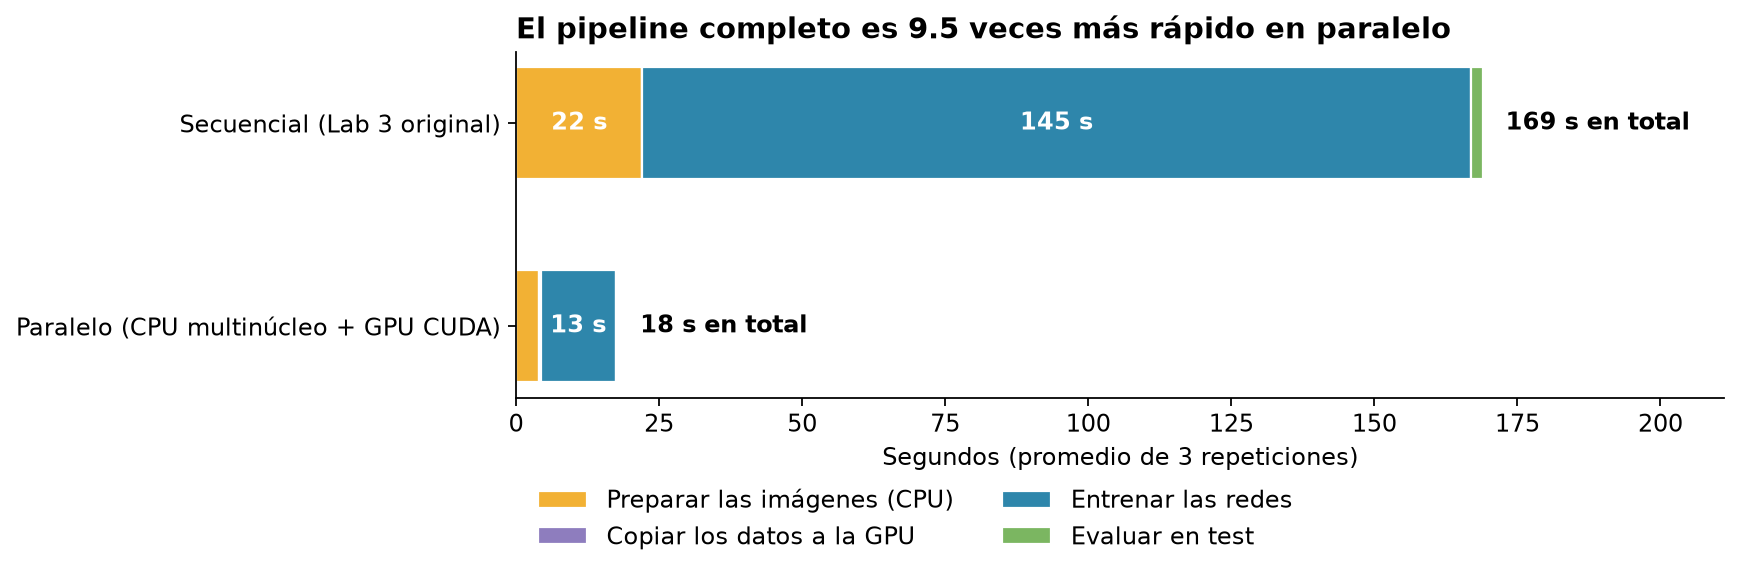

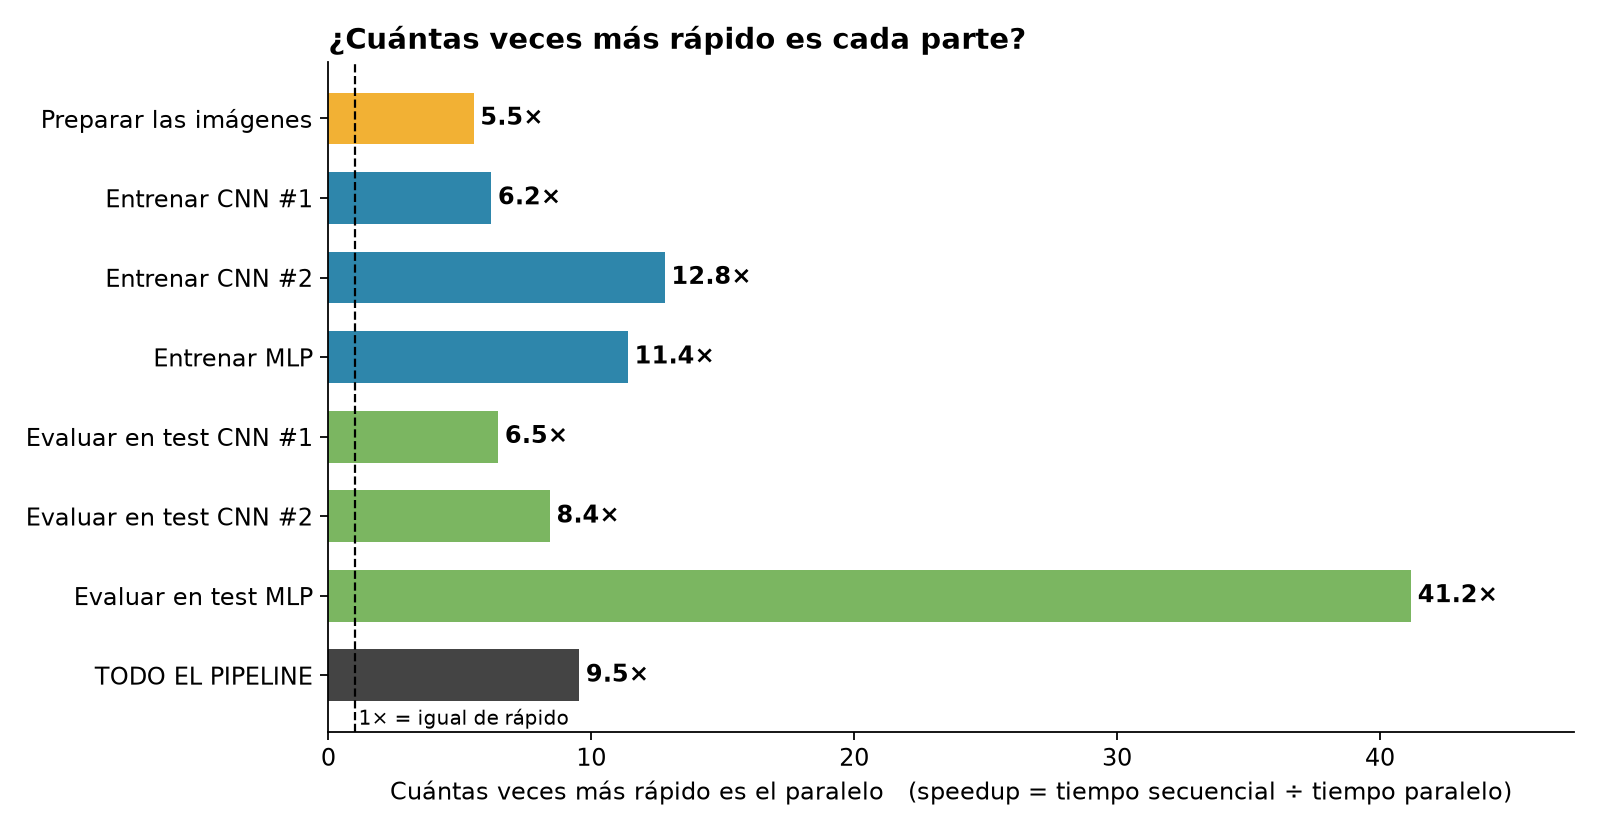

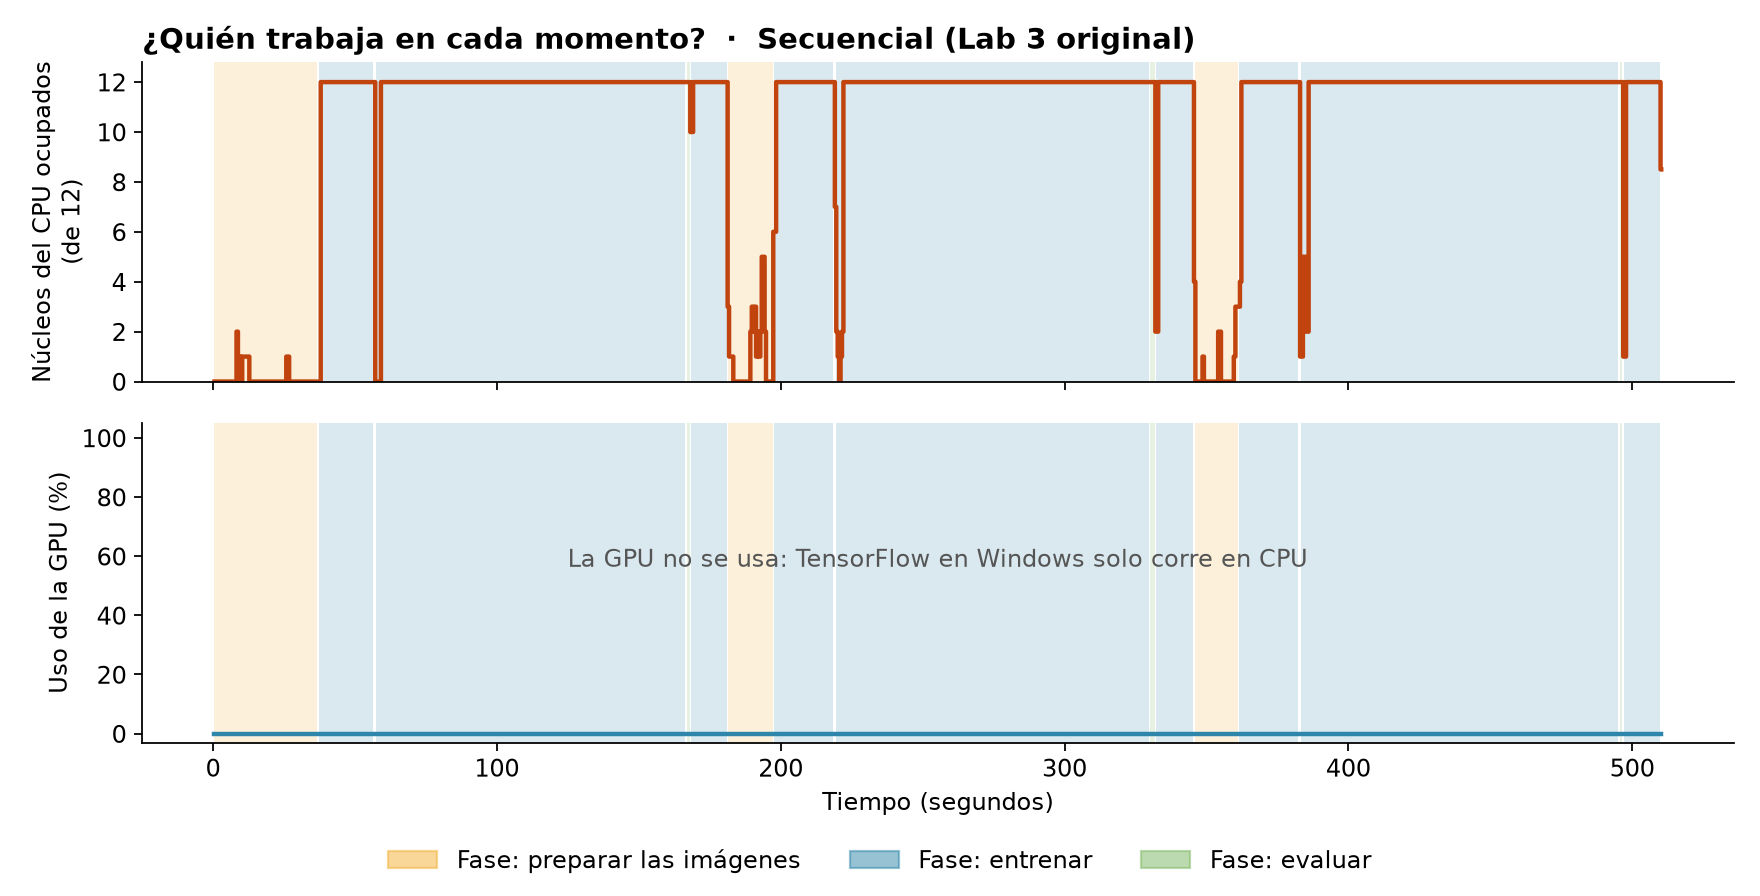

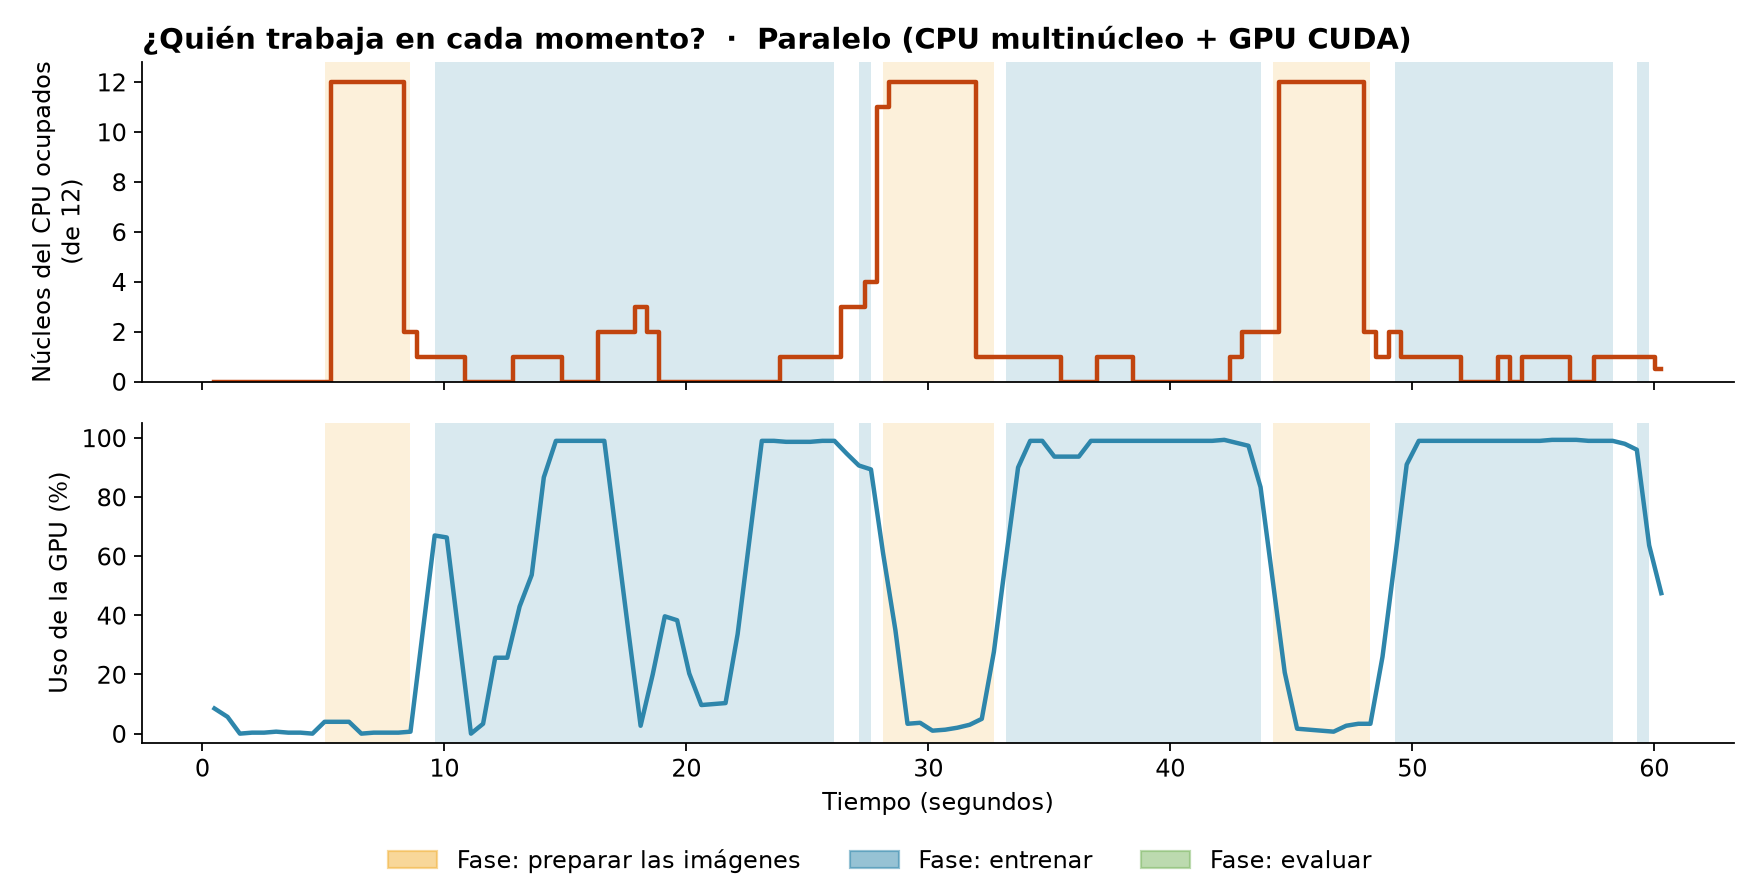

In [11]:
display(Markdown((ROOT / "results" / "tabla_comparativa_pc2.md").read_text(encoding="utf-8")))
for f in ["1_tiempo_total_pc2.png", "2_speedup_por_fase_pc2.png", "3_uso_recursos_secuencial_pc2.png", "3_uso_recursos_paralelo_pc2.png"]:
    display(Image(filename=str(ROOT / "results" / "figures" / f)))

**Capturas de pantalla** del Administrador de Tareas y de `nvidia-smi` durante las ejecuciones (`evidencia/`):

**Secuencial · preparación de imágenes (carga baja)**

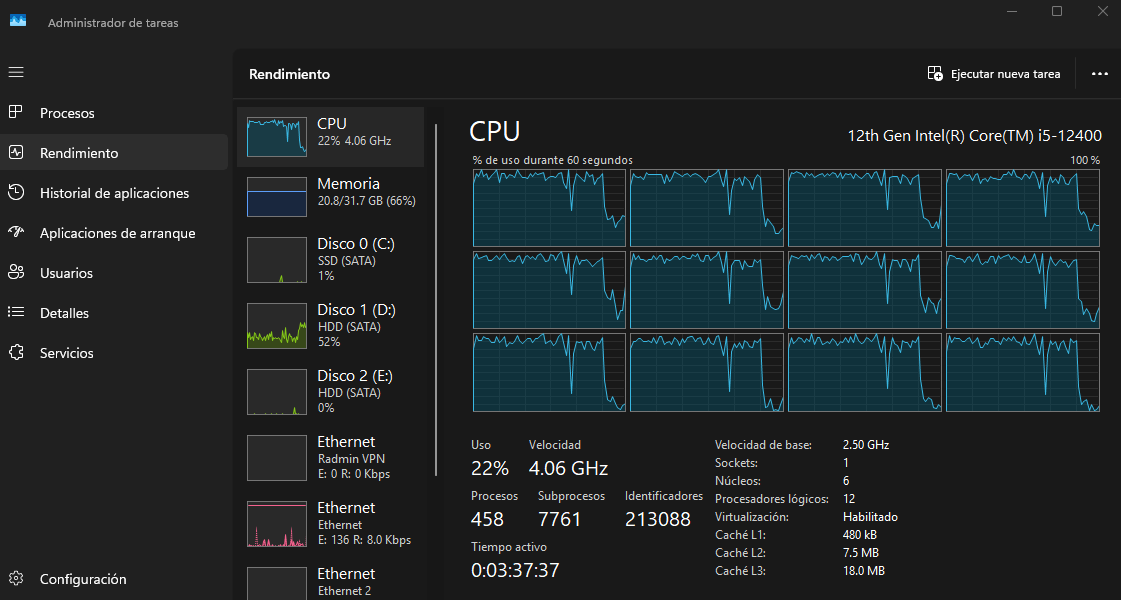

**Secuencial · entrenamiento: 12 núcleos al máximo**

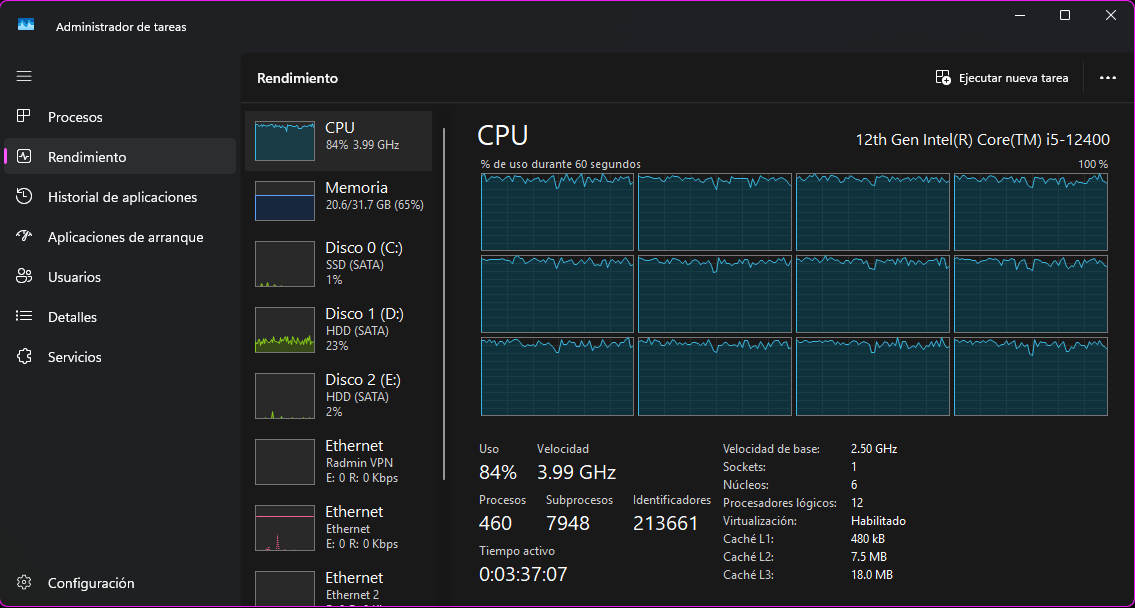

**Secuencial · GPU sin trabajo**

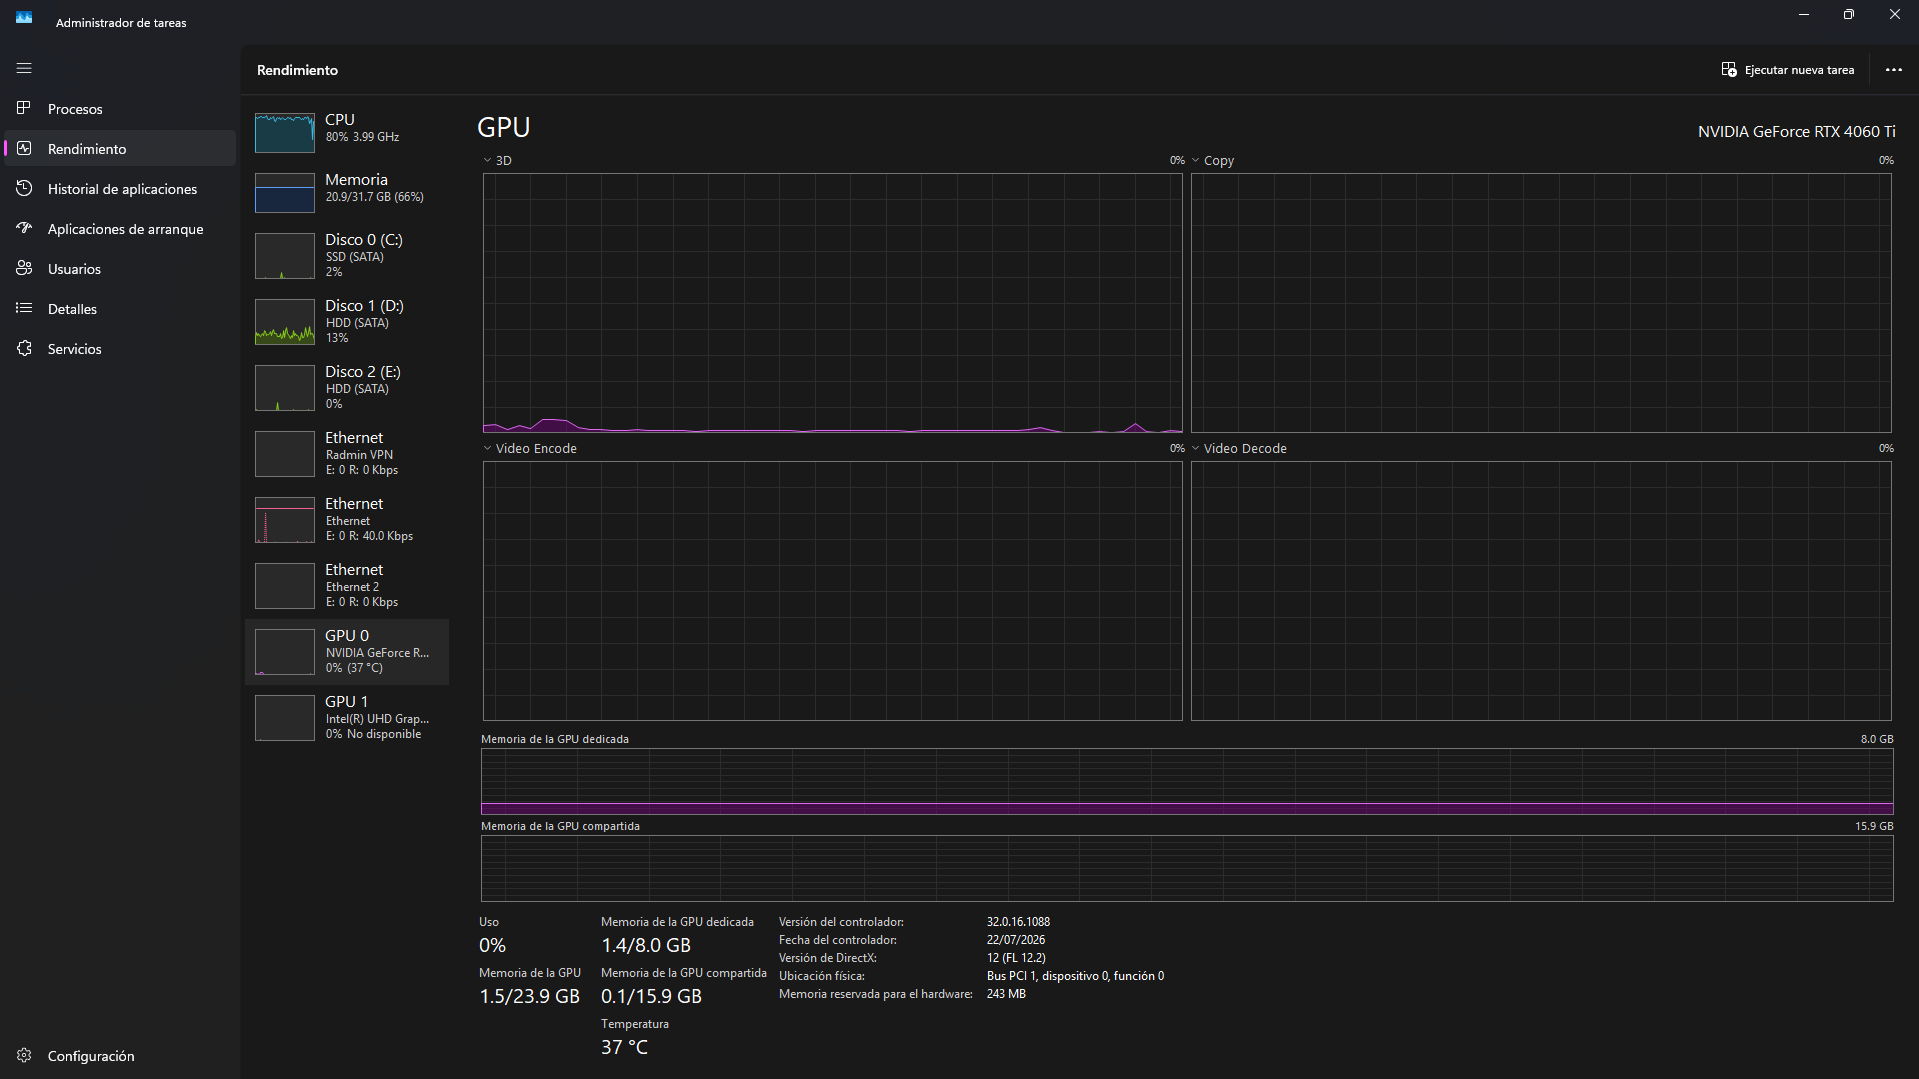

**Paralelo · preparación: pico en los 12 núcleos**

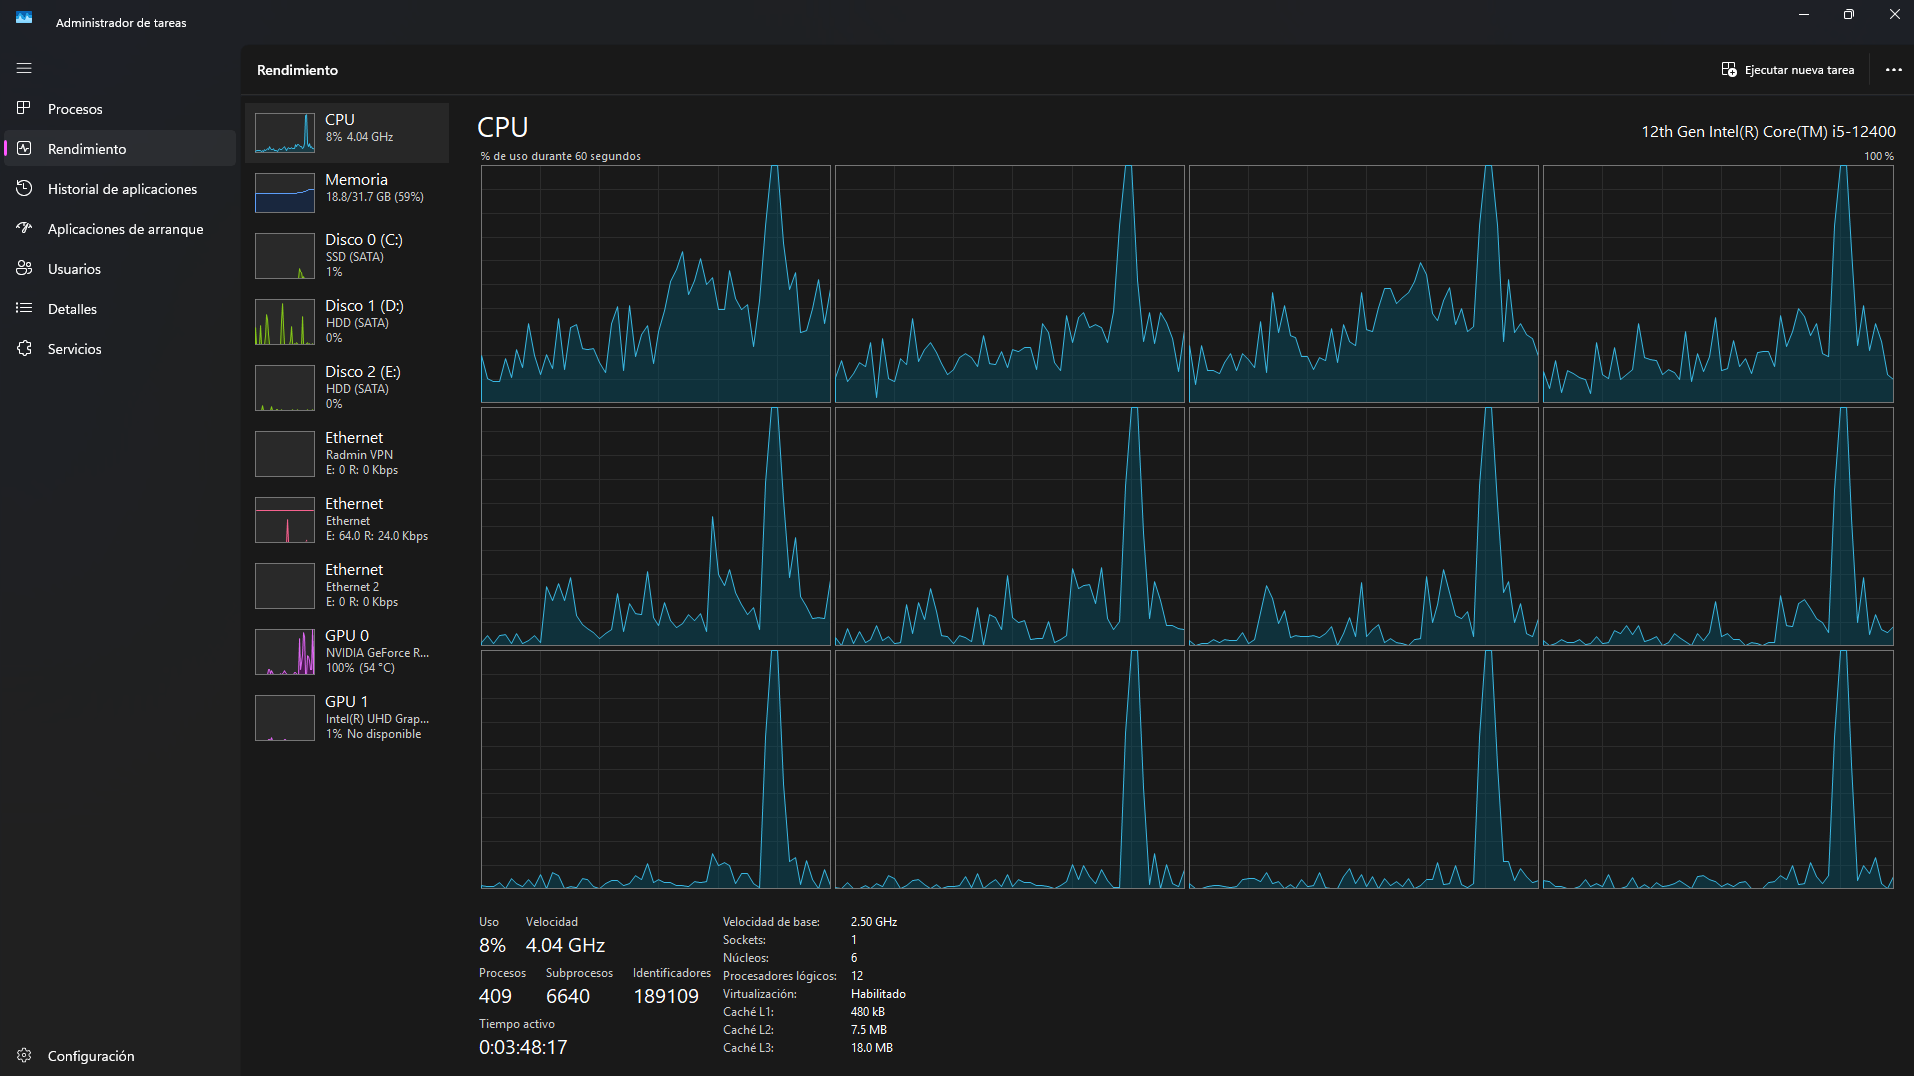

**Paralelo · entrenamiento: GPU al 93 %**

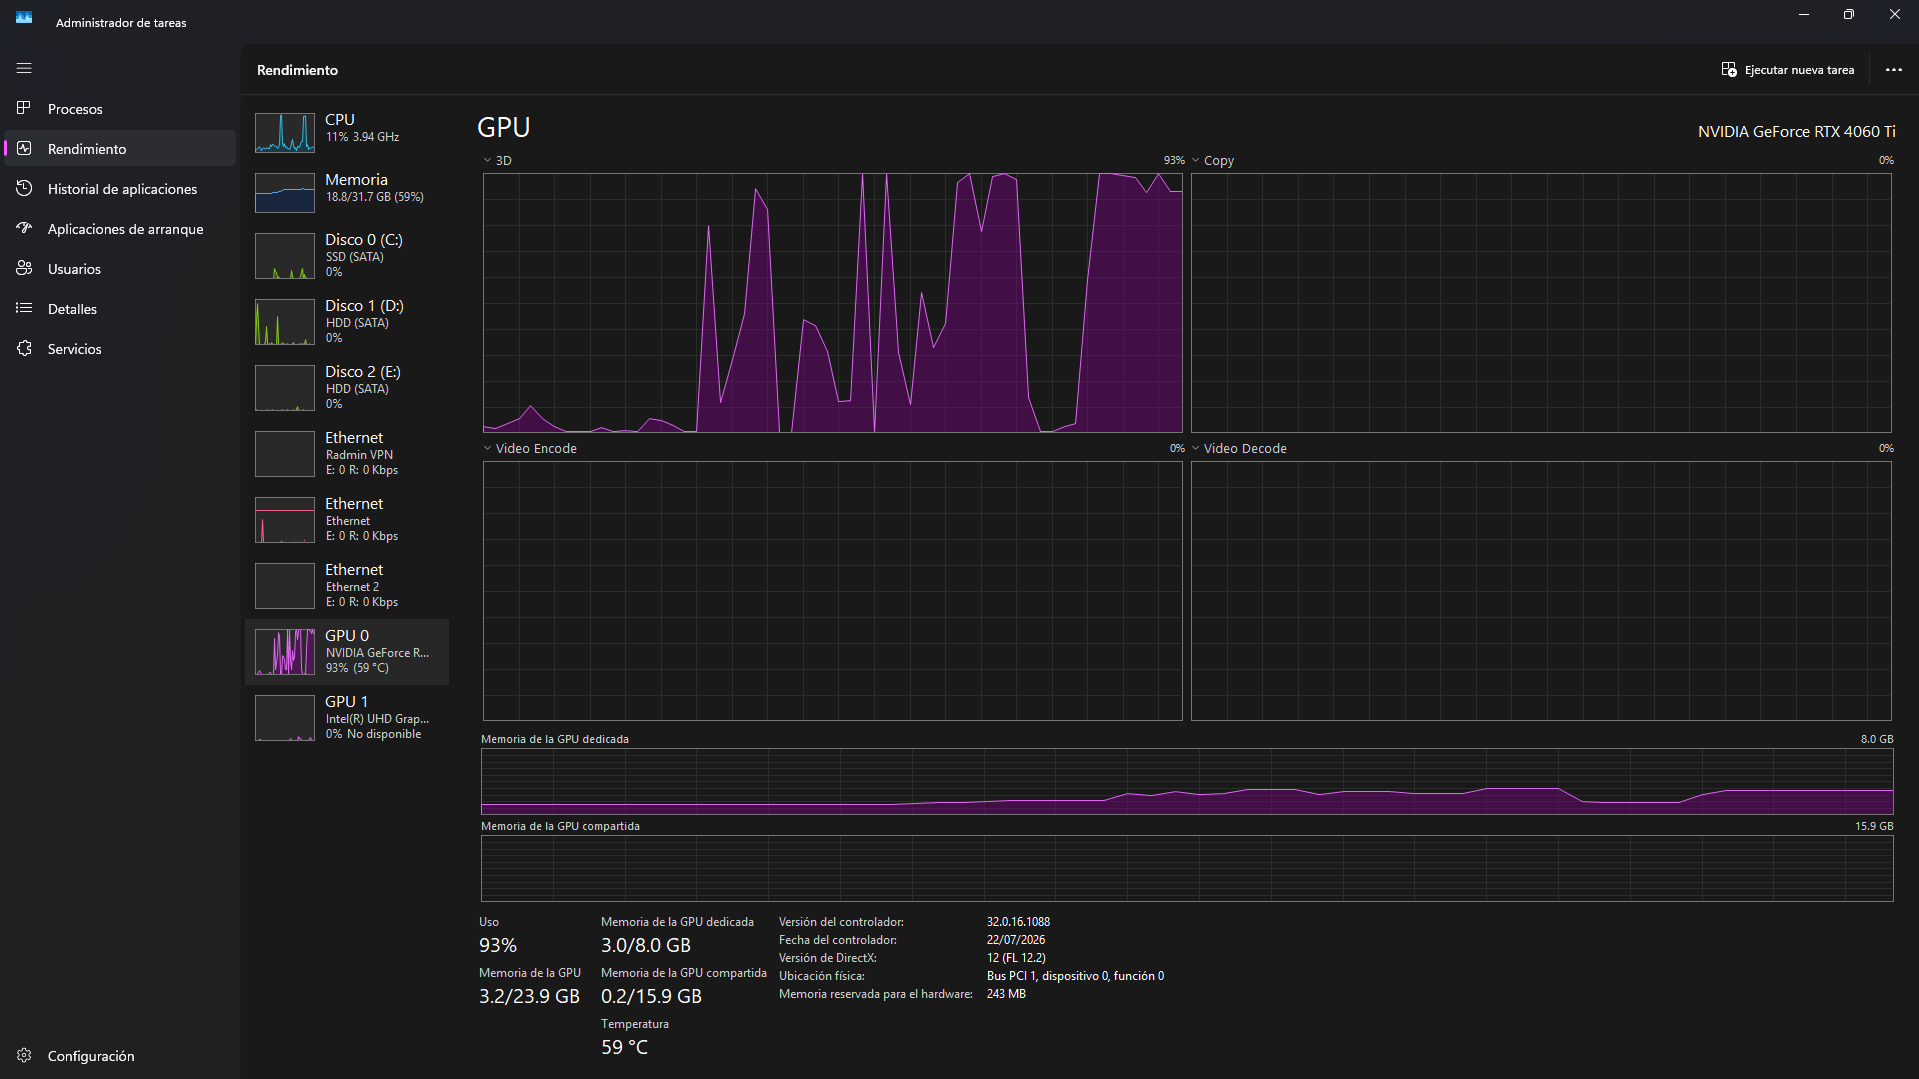

**Paralelo · nvidia-smi: GPU al 99 %**

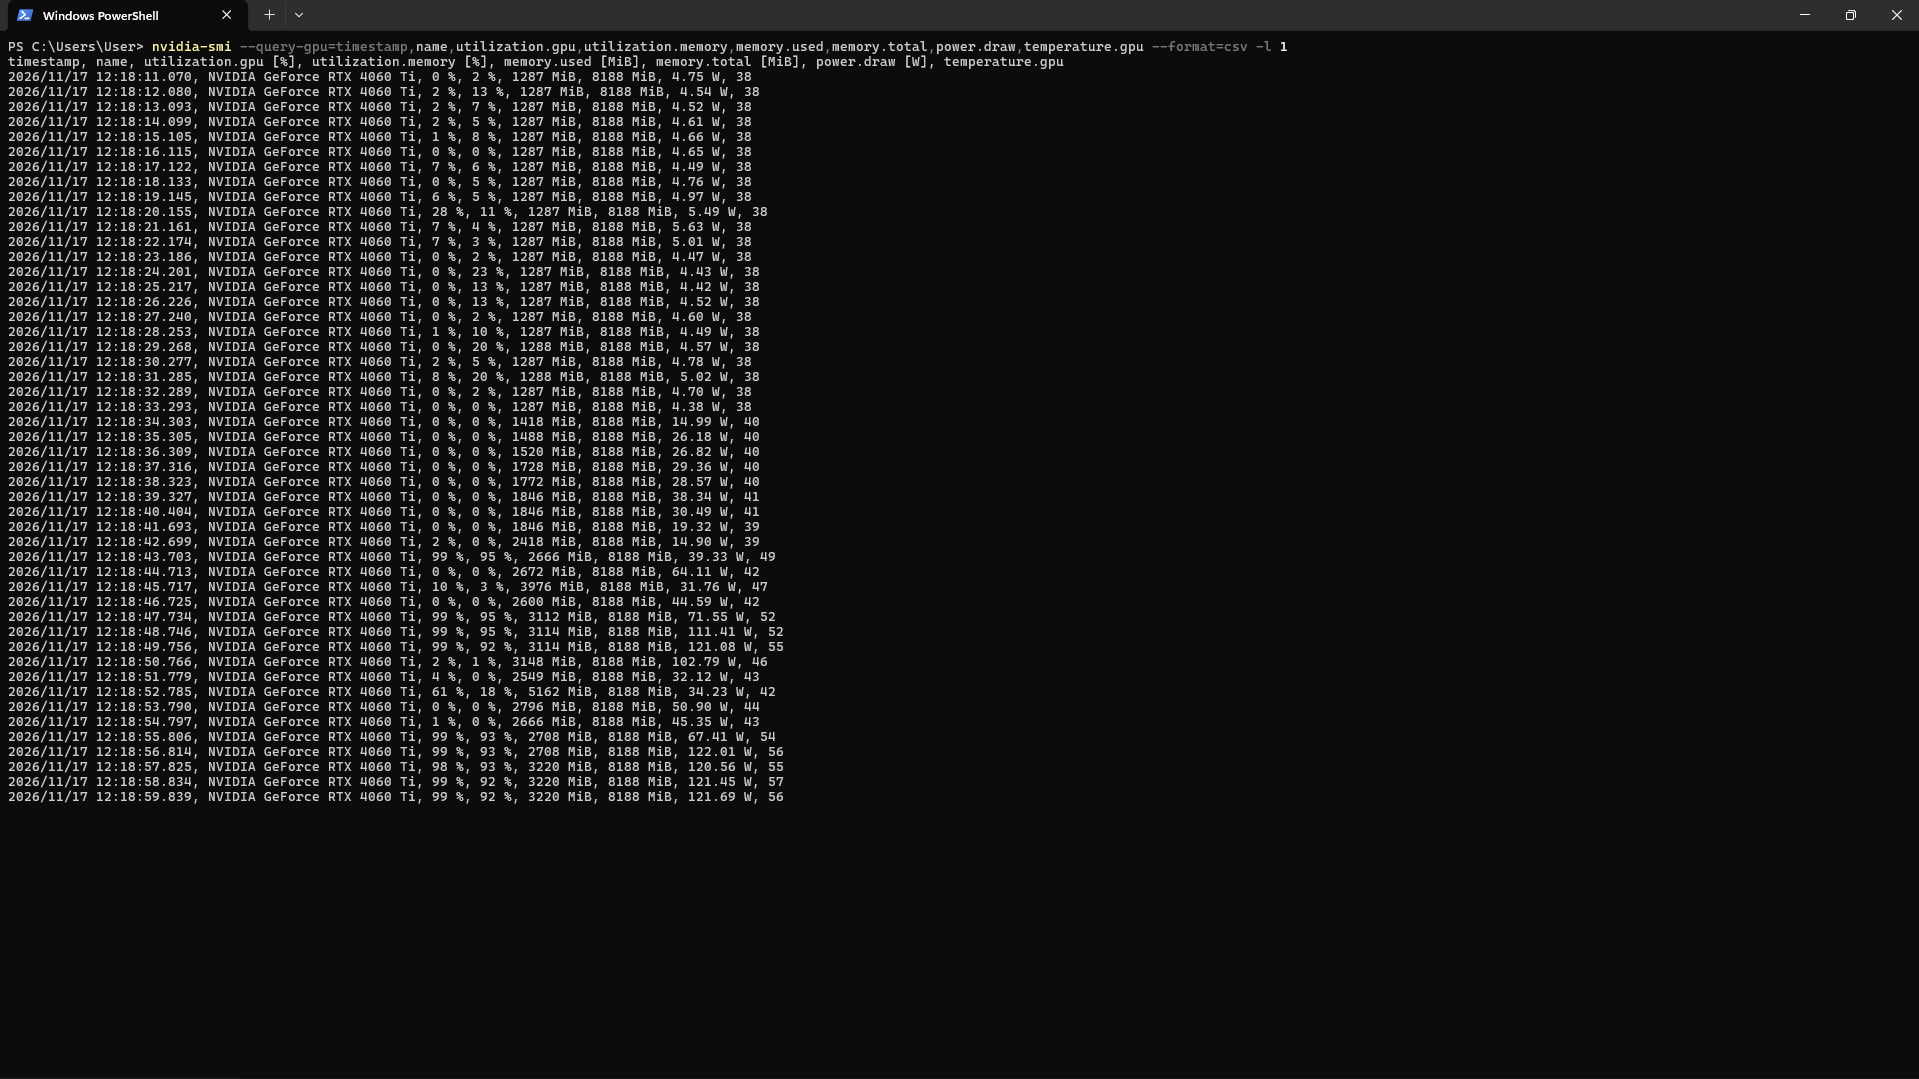

In [12]:
for f, t in [
    ("pc2_secuencial_preparando_cpu.png", "Secuencial · preparación de imágenes (carga baja)"),
    ("pc2_secuencial_entrenando_cpu.png", "Secuencial · entrenamiento: 12 núcleos al máximo"),
    ("pc2_secuencial_entrenando_gpu.png", "Secuencial · GPU sin trabajo"),
    ("pc2_paralelo_preparando_cpu.png", "Paralelo · preparación: pico en los 12 núcleos"),
    ("pc2_paralelo_entrenando_gpu.png", "Paralelo · entrenamiento: GPU al 93 %"),
    ("pc2_paralelo_entrenando_nvidia-smi.png", "Paralelo · nvidia-smi: GPU al 99 %"),
]:
    display(Markdown(f"**{t}**"))
    display(Image(filename=str(ROOT / "evidencia" / f), width=900))

## 6. Paso 6: análisis y conclusiones

## 6.1 Equipo y protocolo de medición

| | |
|---|---|
| CPU | Intel Core i5-12400 · 6 núcleos / 12 hilos |
| GPU | NVIDIA GeForce RTX 4060 Ti · 8 GB · 34 multiprocesadores (SM) · capacidad de cómputo 8.9 |
| RAM / SO | 31.7 GB · Windows 11 |
| Software | Python 3.12 · secuencial: TensorFlow 2.21 / Keras 3.15 (sin GPU en Windows nativo) · paralelo: PyTorch 2.11 + CUDA 12.8 |
| Datos | 17,400 imágenes de la muestra del Lab 3 (12,180 entrenamiento, 2,610 validación, 2,610 prueba), 64 × 64 × 3 |
| Parámetros | 3 épocas fijas, lote de 64, mismos hiperparámetros del Lab 3, 3 repeticiones por versión |

Datos crudos: `results/benchmark_pc2_keras_original.csv` y `results/benchmark_pc2_cuda.csv`. Tablas y gráficos generados
con `comparacion/comparar.py` (`results/tabla_comparativa_pc2.md`, `results/figures/`).

**Qué entra en el tiempo del paralelo:** preparar las imágenes (CPU), la copia de los datos a la GPU (transferencia
CPU → GPU, 816 MiB), el entrenamiento y la evaluación, con `torch.cuda.synchronize()` antes de cada lectura del reloj
(los kernels CUDA son asíncronos). **Qué no entra:** la inicialización única de CUDA (contexto + autotune de cuDNN),
**5.0 s**, que se mide aparte (`cuda_warmup`) y se paga una sola vez al abrir el programa.

## 6.2 Comparación de tiempos y speedup

Tiempo en segundos, media ± desviación estándar de 3 repeticiones. *Speedup = tiempo secuencial ÷ tiempo paralelo.*

| Fase | Modelo | Secuencial (s) | Paralelo CUDA (s) | **Speedup** |
|---|---|---:|---:|---:|
| Preparar las imágenes (CPU) | — | 22.08 ± 12.20 | 3.99 ± 0.43 | **5.53×** |
| Copiar los datos a la GPU | — | — | 0.30 ± 0.05 | (solo existe en el paralelo) |
| Entrenar | CNN #1 | 20.70 ± 1.14 | 3.34 ± 1.73 | **6.20×** |
| Entrenar | CNN #2 | 110.92 ± 1.19 | 8.67 ± 2.66 | **12.80×** |
| Entrenar | MLP | 13.11 ± 0.34 | 1.15 ± 0.03 | **11.40×** |
| Evaluar en test | CNN #1 | 0.41 ± 0.02 | 0.06 ± 0.00 | 6.47× |
| Evaluar en test | CNN #2 | 1.55 ± 0.04 | 0.18 ± 0.00 | 8.43× |
| Evaluar en test | MLP | 0.17 ± 0.00 | 0.004 | ≈ 41× (ver nota) |
| **TOTAL del pipeline** | | **168.94 ± 9.77** | **17.70 ± 4.00** | **9.55×** |

*Nota sobre «Evaluar MLP»: dura 4 ms, tan poco que el cociente es muy sensible a cualquier variación; no se debe leer
como una aceleración real de 41×.*



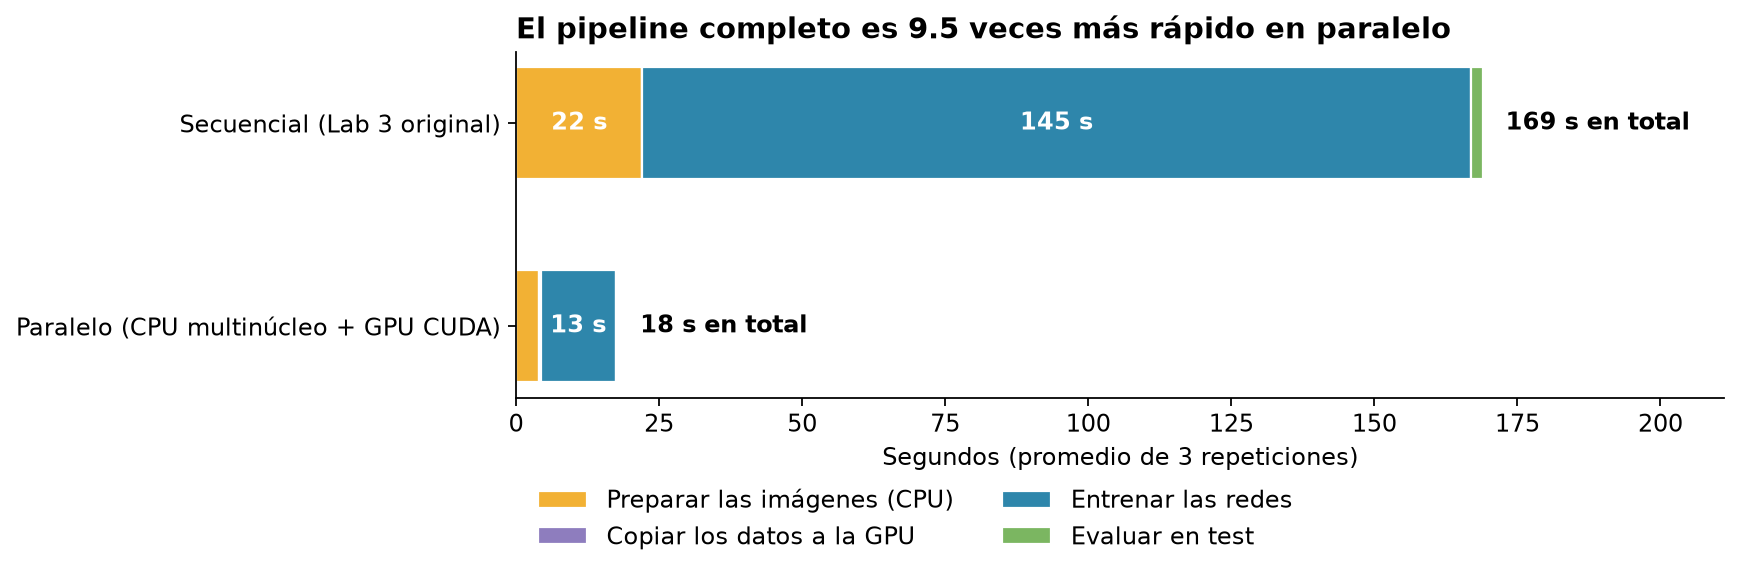

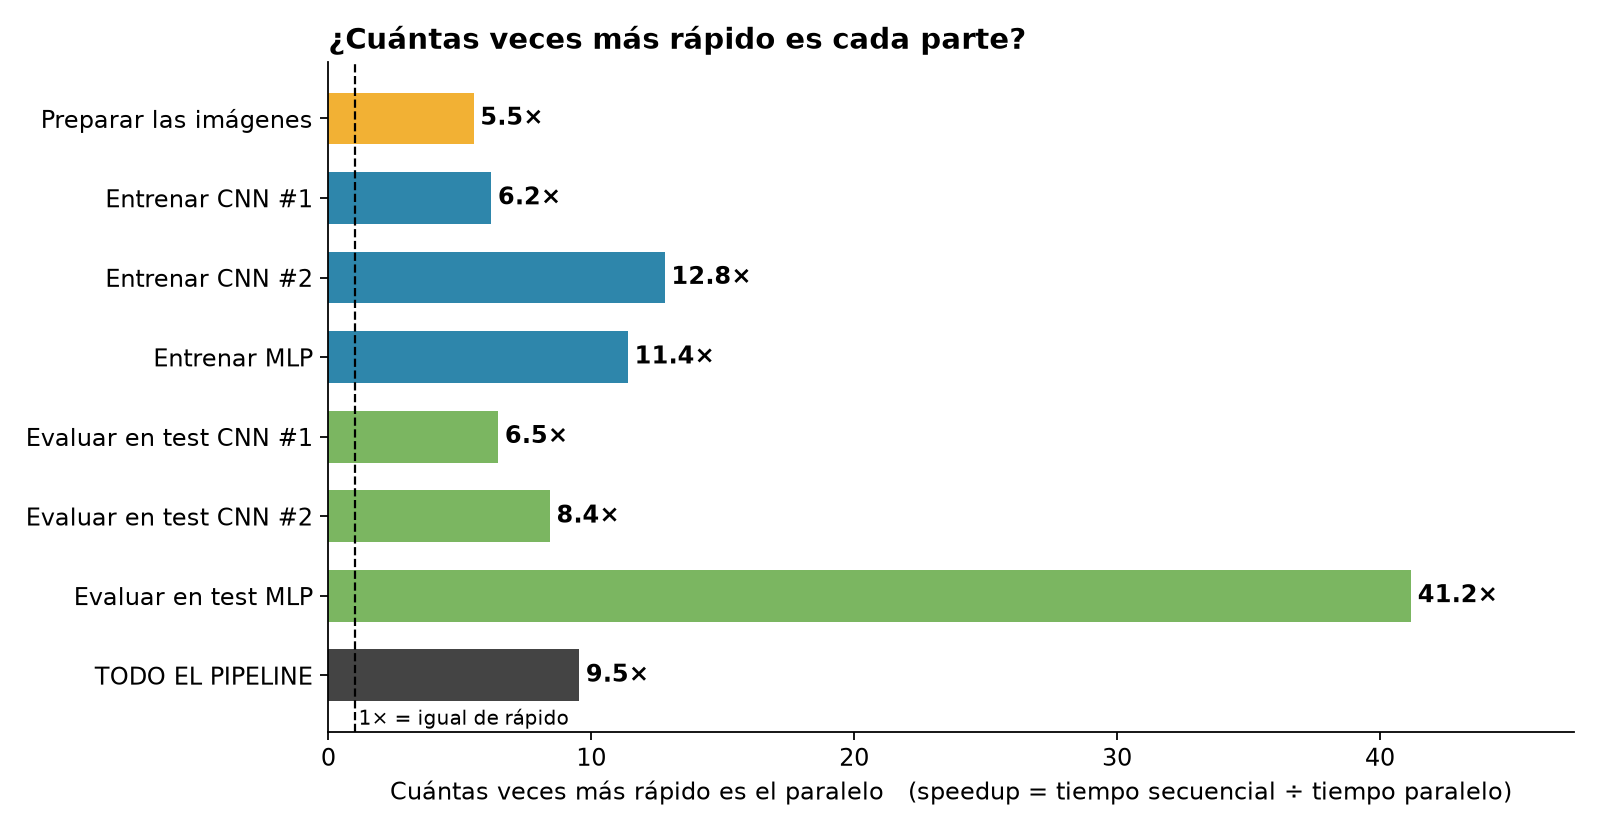



### Dos salvedades que afectan las cifras

1. **Repetición 1 del secuencial (preparación de imágenes).** Tardó 36.2 s y las repeticiones 2 y 3 tardaron 15.2 y
   14.9 s. Las imágenes están en un disco duro (HDD) y en la primera lectura no estaban en la caché del sistema; el
   script secuencial no calienta la caché, el paralelo sí (`warm_file_cache`). De ahí la desviación de ±12.2 s.
2. **Repetición 1 del paralelo (entrenamiento).** La CNN #1 tardó 5.3 s y la CNN #2 11.7 s, contra 2.3 s y 7.1 s en las
   repeticiones 2 y 3 (que coinciden casi exactamente entre sí). La explicación probable es que la GPU venía de reposo y
   tardó en subir de frecuencia; **es una hipótesis, no se verificó.**

Por eso se reporta también la comparación con ambos equipos «en caliente» (repeticiones 2 y 3 de cada versión):

| Fase | Modelo | Secuencial reps 2-3 (s) | Paralelo reps 2-3 (s) | Speedup |
|---|---|---:|---:|---:|
| Preparar las imágenes | — | 15.04 | 4.22 | 3.56× |
| Entrenar | CNN #1 | 21.36 | 2.34 | 9.13× |
| Entrenar | CNN #2 | 111.55 | 7.13 | **15.64×** |
| Entrenar | MLP | 13.21 | 1.13 | 11.67× |
| **TOTAL** | | **163.30** | **15.39** | **10.61×** |

**Conclusión de la comparación:** la paralelización redujo el tiempo total de **169 s a 18 s** (9.5×; 10.6× en
condiciones de equipo caliente). El mayor beneficio está en entrenar, y dentro de eso en la CNN #2, la red con más
cálculo (12.8× a 15.6×). La preparación de imágenes mejora menos (3.6× a 5.5×).

## 6.3 Por qué el speedup tiene este valor

**Ley de Amdahl.** En el secuencial, entrenar y evaluar son el 86.9 % del tiempo (144.7 + 2.1 de 168.9 s). Si solo esa
parte se acelerara, el máximo sería 1 / (1 − 0.869) ≈ **7.6×**. Se obtuvo 9.55× porque *además* se paralelizó la
preparación de imágenes (el otro 13 %); sin ese segundo cambio no se habría pasado de 7.6×.

**El cuello de botella cambió de lugar.** En el paralelo, la preparación de imágenes ya es el **22.6 %** del total
(3.99 de 17.70 s) y entrenar el 74.4 %. Entrenar pasó de ser el 85.7 % del tiempo a ser el 74.4 % de un tiempo 9.5 veces
menor; lo siguiente a optimizar sería la preparación.



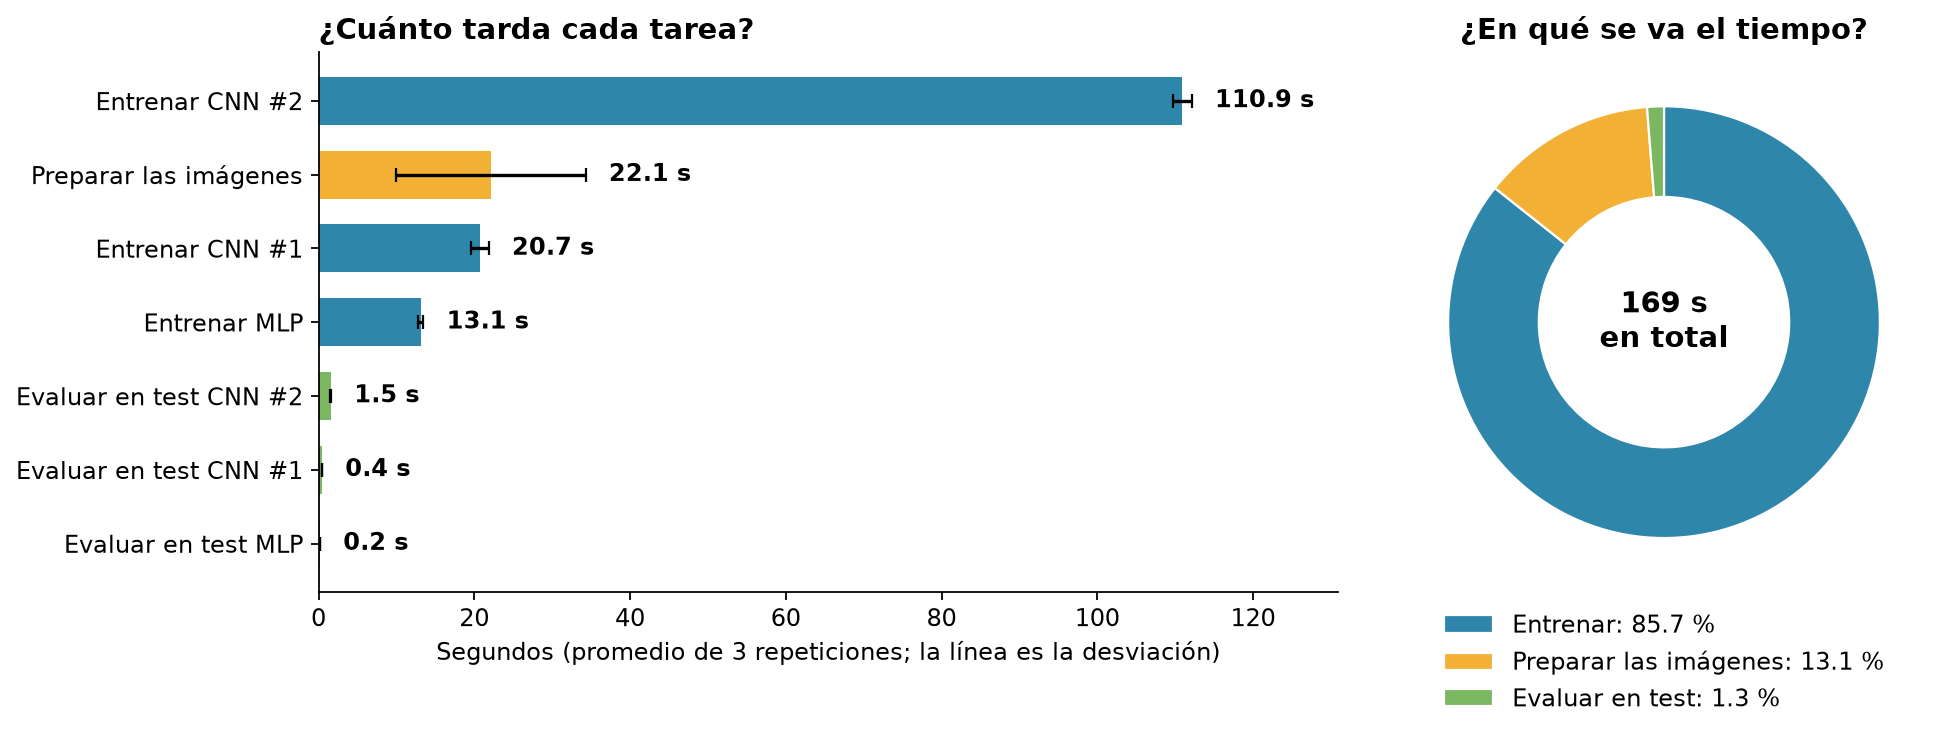



**Causas por fase:**

| Fase | Causa de la diferencia |
|---|---|
| Entrenar (6× a 15×) | Las convoluciones, capas densas y la actualización de Adam son millones de operaciones independientes sobre tensores; la GPU las reparte en miles de hilos (34 SM × hasta 1,536 hilos residentes = 52,224 hilos a la vez), mientras que el CPU dispone de 12 hilos. La CNN #2 gana más porque tiene más aritmética por imagen (≈ 118.9 millones de multiplicaciones, 4.9 veces la CNN #1), y hay más trabajo que repartir entre los hilos de la GPU. |
| Entrenar CNN #1 (6.2×) | Es una red pequeña: con menos cálculo por lote, el costo fijo de lanzar kernels pesa más y la GPU se aprovecha menos. |
| Preparar imágenes (3.6× a 5.5×) | Se reparte en 12 procesos, pero el CPU tiene 6 núcleos físicos (los 12 hilos comparten recursos), decodificar JPEG no escala perfecto, y arrancar los procesos y juntar los resultados tiene costos fijos. Además depende del disco. |
| Evaluar (6× a 8×) | Mismo cálculo de la propagación hacia adelante, ya con los datos en la memoria de la GPU. |
| Copia a la GPU | 816 MiB en 0.30 s (≈ 2.7 GB/s), el 1.7 % del tiempo. Se hace una sola vez, no por lote. |

El speedup de cada fase depende también de qué tan buena sea la referencia: el MLP, por ejemplo, mejora 11× en parte
porque en el secuencial era lento para lo poco que calcula, no solo por mérito de la GPU.

## 6.4 Evidencia de uso de los recursos

Cada fase usa el hardware que le corresponde. Promedios de los logs automáticos (`logs/resources_pc2_*.csv`, CPU por
núcleo con `psutil` y GPU con NVML):

| Versión | Fase | CPU | Núcleos > 50 % | GPU |
|---|---|---:|---:|---:|
| Secuencial | Preparar imágenes | 20 % | 0 de 12 | 4 % |
| Secuencial | Entrenar | 91 % | 12 de 12 | 5 % (no usa la GPU) |
| Paralelo | Preparar imágenes | 84 % | **12 de 12** | 2 % |
| Paralelo | Entrenar | **18 %** | 0 de 12 | **76 %** (80 % medio, picos de 100 %) |

La VRAM máxima durante el entrenamiento fue de ≈ 4.4 GB (incluye ≈ 1.2 GB que ya usa Windows); la GPU llegó a ~124 W y 59 °C.



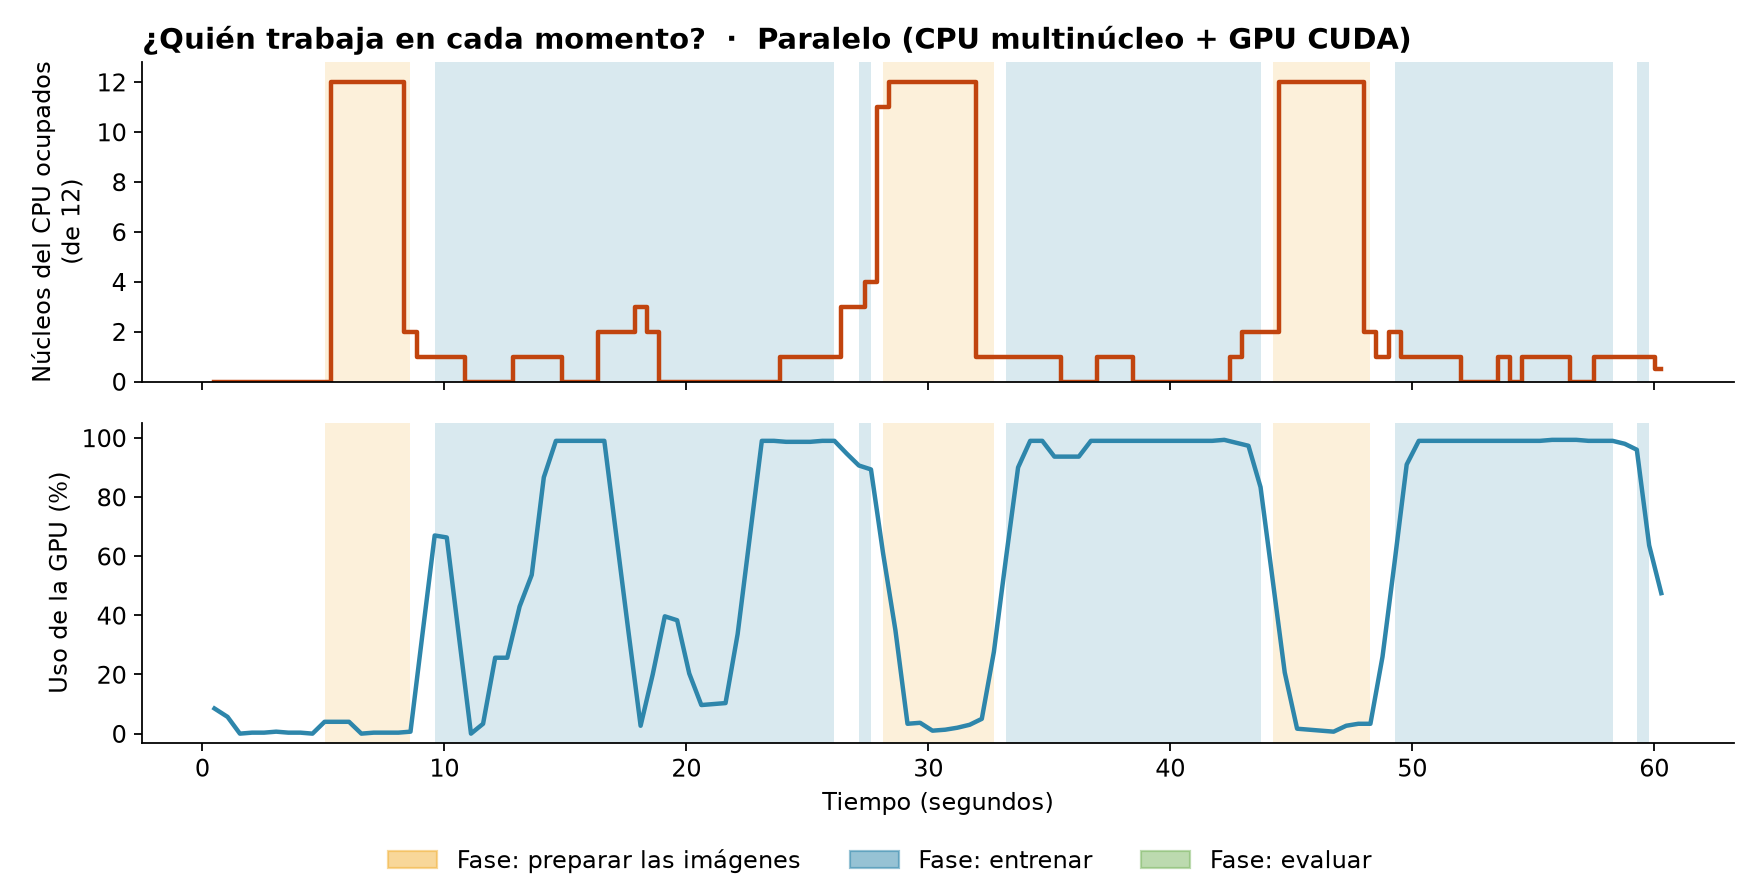

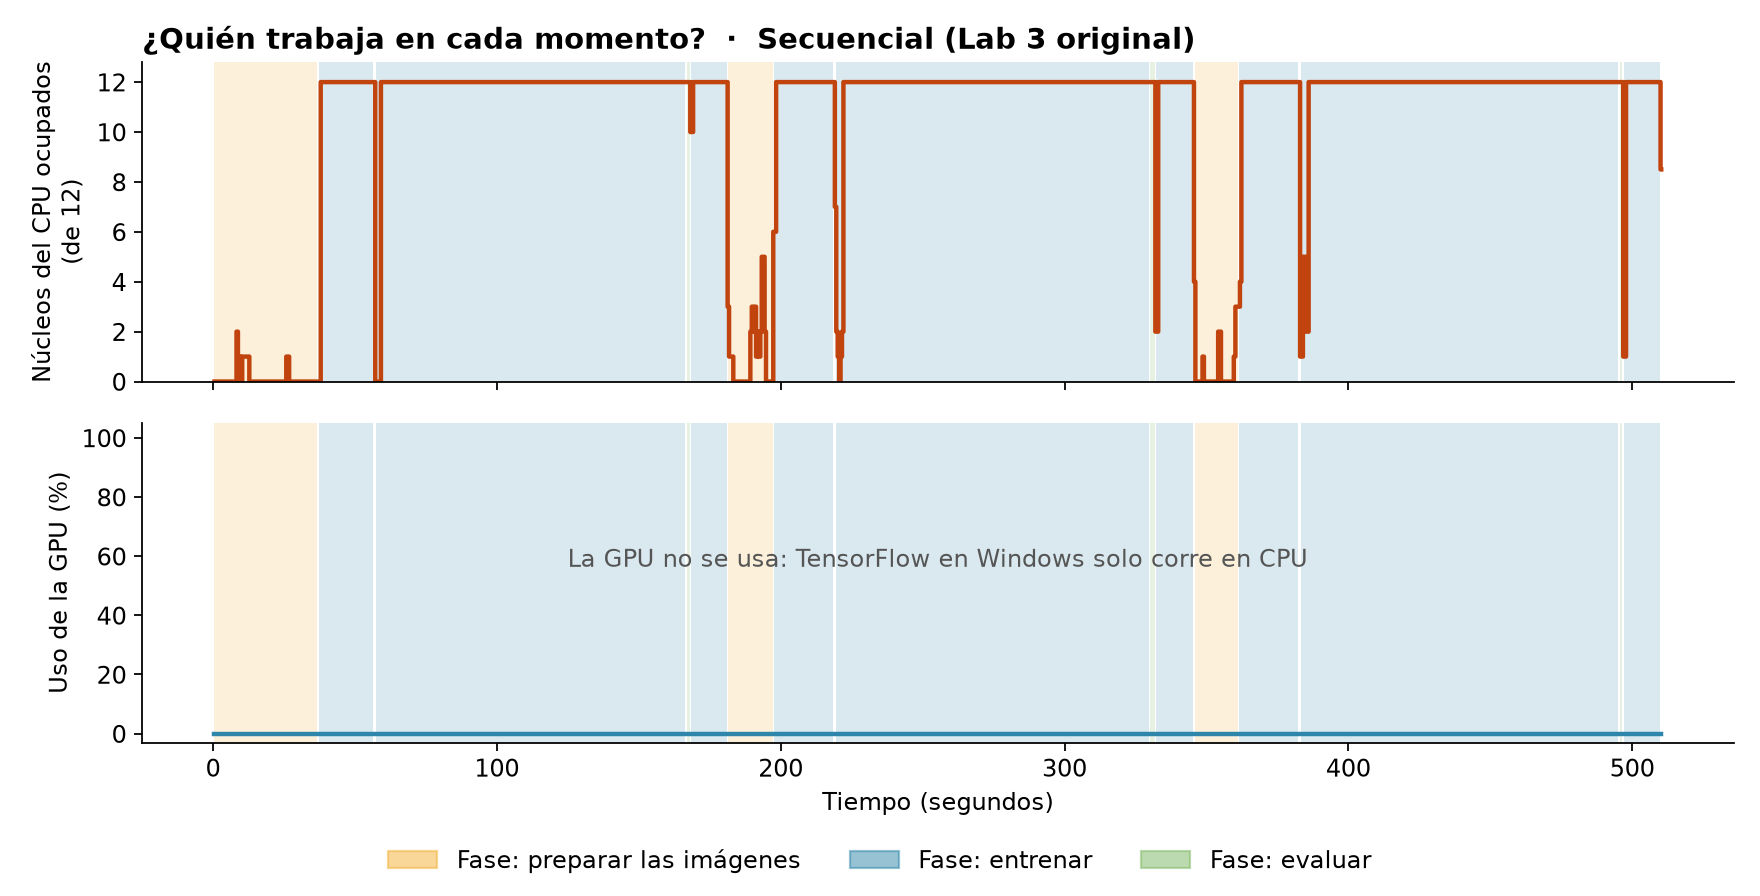



**Capturas de pantalla** (`evidencia/`):

| Captura | Qué muestra |
|---|---|
| `pc2_secuencial_preparando_cpu.png` | Inicio de la preparación (CPU 22 %, disco D: activo): carga baja, no los 12 núcleos |
| `pc2_secuencial_entrenando_cpu.png` | Entrenamiento secuencial: los 12 núcleos casi al 100 % |
| `pc2_secuencial_entrenando_gpu.png` | GPU en 0 % durante el secuencial (Keras en Windows no la usa) |
| `pc2_paralelo_preparando_cpu.png` | Pico simultáneo en los 12 núcleos durante la preparación en paralelo |
| `pc2_paralelo_entrenando_gpu.png` | GPU al 93 %, 3.0 GB de VRAM dedicada y CPU en 11 % |
| `pc2_paralelo_entrenando_nvidia-smi.png` | `nvidia-smi`: GPU al 99 %, memoria de 1.3 a 5.1 GB, ≈ 121 W |

> En el Administrador de Tareas de este equipo, el trabajo de CUDA aparece en el panel **«3D»** de la GPU (el menú no
> ofrece un motor «Cuda» separado); `nvidia-smi` confirma la misma carga. En el secuencial, el Administrador de Tareas
> no muestra «un solo núcleo» limpio porque Windows va rotando el único hilo entre los 12 núcleos; la evidencia
> cuantitativa de que solo trabaja ~1 núcleo son los logs de la tabla anterior.

## 6.5 Kernel CUDA propio (Numba, «CUDA Python» explícito)

Además de las bibliotecas, se implementó un kernel propio para el paso de **Adam** (operación 14 del diseño) en
`paralelo_cuda/kernel_adam_numba.py`, con la geometría de la tabla del Paso 4: **un hilo por parámetro, bloques de 256
hilos, ⌈N / 256⌉ bloques** (para la CNN #2, N = 2,245,437 → 8,772 bloques si fuera un solo lanzamiento; en la
implementación se lanza un kernel por tensor de parámetros, 26 en total). Comparte memoria con PyTorch sin copiarla
(`numba.cuda.as_cuda_array`).

| | Resultado (`results/kernel_adam_numba_pc2.csv`) |
|---|---|
| Validación contra `torch.optim.Adam` (10 pasos) | error máximo absoluto **2.2 × 10⁻⁸** → correcto |
| Tiempo por paso, `torch.optim.Adam` | 0.38 ms |
| Tiempo por paso, kernel de Numba | 3.91 ms (≈ 10× más lento) |

El kernel es correcto pero **más lento** que el optimizador de PyTorch. Es coherente con que el costo está en lanzar 26
kernels por paso desde Python (más la preparación de argumentos de Numba) y no en el cálculo; PyTorch agrupa esas
actualizaciones. No se verificó con un perfilador. Este kernel se mide por separado y **no está integrado en el bucle de
entrenamiento medido**, cuyos tiempos usan `torch.optim.Adam`. Para ejecutarlo hay dos requisitos del entorno:
`numba-cuda[cu12]` con NumPy < 2.4, y cargar `nvJitLink` antes de importar `torch` (si no, el enlazado falla).

## 6.6 Discusión técnica

### ¿Por qué procesar las imágenes con los núcleos del CPU y delegar *exclusivamente* la matemática de la red a la GPU?

* **Leer archivos lo hace el sistema operativo, no la GPU.** El disco y las rutas de archivo son del CPU; la GPU no abre
  archivos.
* **Decodificar JPEG tiene muchas bifurcaciones y poca aritmética por dato**, justo lo contrario de lo que la GPU hace
  bien (mucha aritmética regular sobre muchos datos). Cada imagen es independiente, así que se reparte entre procesos
  del CPU sin comunicación entre ellos.
* **Se hace una sola vez**, no en cada época. Mover esa lógica a la GPU complicaría el código para acelerar una fase
  que ya pesa poco.
* **La matemática de la red sí encaja con la GPU:** convoluciones, multiplicaciones de matrices, BatchNorm, pérdida y
  Adam son operaciones sobre millones de valores independientes, y se repiten en cada lote de cada época.
* **Cada recurso trabaja en su fase y nunca compiten:** los logs lo muestran (CPU 84 % / GPU 2 % al preparar; CPU 18 % /
  GPU 76 % al entrenar). La única copia entre ambos son 816 MiB, una vez (1.7 % del tiempo); desde ahí cada lote se
  toma de la memoria de la GPU sin volver a pasar por el CPU.

### ¿Cómo permitió CUDA reducir o cambiar el tiempo de procesamiento?

Cambió **dónde y cómo** se hace el cálculo: en lugar de 12 hilos del CPU, la GPU ejecuta decenas de miles de hilos que
calculan a la vez los valores de cada capa (la convolución más grande de la CNN #2 tiene 8.4 millones de valores de
salida independientes por lote). Esto redujo el entrenamiento de 144.7 s a 13.2 s (11×) y el total de 168.9 s a 17.7 s
(9.5×). Además, al ser el entrenamiento mucho más rápido, **cambió el perfil del programa:** la preparación de imágenes
pasó de ser el 13 % al 22.6 % del tiempo.

### ¿Qué factores justifican o limitan la utilización de CUDA?

| Justifican | Limitan |
|---|---|
| Mucho cálculo por dato (la CNN #2 gana 12.8× a 15.6×) | Redes pequeñas o poco cálculo: el costo fijo de lanzar kernels pesa más (CNN #1: 6.2×; MLP evaluando: 4 ms) |
| Operaciones independientes sobre tensores grandes | Fracción no acelerable (Amdahl): preparar imágenes, control del programa |
| Datos que caben en la VRAM y se copian una sola vez (816 MiB de 8 GB) | Si no caben, o se copian por lote, la transferencia CPU ↔ GPU domina |
| El mismo cálculo se repite en cada lote y época (el costo de arrancar se amortiza) | **Costos de arranque:** 5.0 s de inicialización de CUDA; en un entrenamiento de 18 s ya pesan |
| Bibliotecas maduras (cuDNN, cuBLAS) ya optimizadas | Hardware: requiere GPU NVIDIA y driver; en Windows, TensorFlow ≥ 2.11 no la usa, por lo que fue necesario portar las redes a PyTorch |
| | Un kernel propio (Numba) no es automáticamente mejor: el de Adam resultó 10× más lento que el de PyTorch |

## 6.7 Funciones y librerías que permiten trabajar con la GPU

| Librería / función | Para qué se usó |
|---|---|
| **PyTorch con CUDA 12.8** (`torch.cuda`, `tensor.to("cuda")`) | Ejecuta las redes y el entrenamiento en la GPU desde Python; transferencia CPU → GPU |
| **cuDNN** | Convoluciones, BatchNorm y pooling (PyTorch delega en ella; se activa `torch.backends.cudnn.benchmark = True`, que elige el algoritmo más rápido en el calentamiento) |
| **cuBLAS** | Multiplicación de matrices de las capas densas (PyTorch delega en ella) |
| `torch.cuda.synchronize()` | Esperar a que la GPU termine antes de leer el reloj (los kernels son asíncronos) |
| `torch.randperm(..., device="cuda")` e indexación en GPU | Mezclar y extraer los lotes sin volver al CPU |
| **Numba CUDA** (`numba.cuda.jit`, `as_cuda_array`) y `numba-cuda[cu12]` | Kernel propio de Adam (6.5) |
| **NVML** (`nvidia-ml-py`) | Monitoreo de uso de GPU, VRAM, potencia y temperatura (mismos datos que `nvidia-smi`) |
| `psutil` | Uso de CPU por núcleo |
| `concurrent.futures.ProcessPoolExecutor` | Repartir las imágenes entre los núcleos del CPU (procesos, no hilos: la decodificación de JPEG no se beneficia de los hilos de Python) |
| `nvidia-smi` y Administrador de Tareas | Evidencia de ejecución (6.4) |

## 6.8 Limitaciones

* **Solo 3 épocas.** Los tiempos miden trabajo por unidad, no la calidad del modelo. Con 3 épocas las redes no han
  convergido, y como PyTorch y Keras inicializan de forma distinta, las precisiones no son comparables entre sí
  (por ejemplo, CNN #2 en validación: 0.41 en PyTorch contra 0.23 en Keras). La referencia de calidad del Lab 3 (CNN #1
  94.2 %, CNN #2 98.0 %) corresponde a un entrenamiento completo, que no se repitió aquí.
* **Una sola máquina** para este análisis. Las mediciones de la otra plataforma (`pc1`, i7-10750H + RTX 2060) quedan en
  el repositorio como segunda referencia, pero no se mezclan con estas cifras.
* **Tres repeticiones** son pocas: la desviación del paralelo (±4.0 s sobre 17.7 s) está dominada por la repetición 1.
* El diseño de hilos y bloques de `docs/04` se calculó para una RTX 2060 (30 SM); esta GPU tiene 34 SM. Las cifras de
  geometría por operación no cambian; solo la capacidad de hilos simultáneos.


In [13]:
mostrar_md(ROOT / "docs" / "06_analisis_y_conclusiones.md", desde="## 6.1")

## 7. Pruebas de equivalencia paralelo / secuencial

`tests/` comprueba que la preparación paralela da **exactamente** el mismo resultado que la secuencial y que las redes
de PyTorch tienen los mismos parámetros que las de Keras del Lab 3.

In [14]:
r = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q"], cwd=ROOT, capture_output=True, text=True,
                   env={**__import__("os").environ, "PYTHONIOENCODING": "utf-8", "PY_COLORS": "0", "NO_COLOR": "1"})
print(re.sub(r"\[[0-9;]*m", "", r.stdout)[-600:])

........                                                                 [100%]
8 passed in 3.12s

